# **Análise Exploratória de Risco de Crédito**

In [39]:
# impoertando bibliotecas
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import matplotlib

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

In [40]:
# carregando o dataset
df = pd.read_csv('../data/cr_loan.csv')

# olhando as estruturas do dataset
df.dtypes

person_age                      int64
person_income                   int64
person_home_ownership             str
person_emp_length             float64
loan_intent                       str
loan_grade                        str
loan_amnt                       int64
loan_int_rate                 float64
loan_status                     int64
loan_percent_income           float64
cb_person_default_on_file         str
cb_person_cred_hist_length      int64
dtype: object

In [41]:
# visualizando as primeiras linhas do dataset
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [42]:
# Analisando a quantidade de nulos no dataset
df.isnull().sum()

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

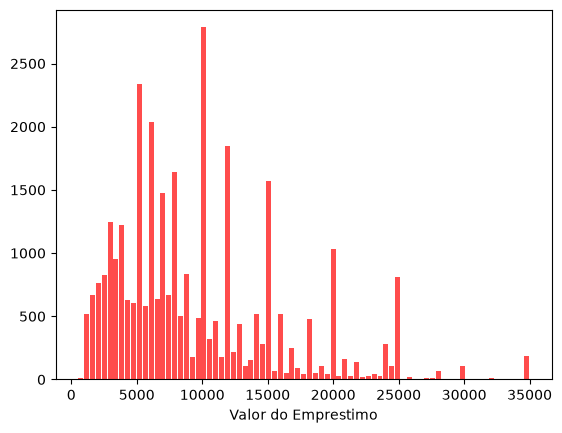

In [43]:
# vendo a distribuição dos valores de emprestimo
n, bins, patches = plt.hist(df['loan_amnt'], bins="auto", color='red', alpha=0.7, rwidth=0.85)
plt.xlabel('Valor do Emprestimo')
plt.show()

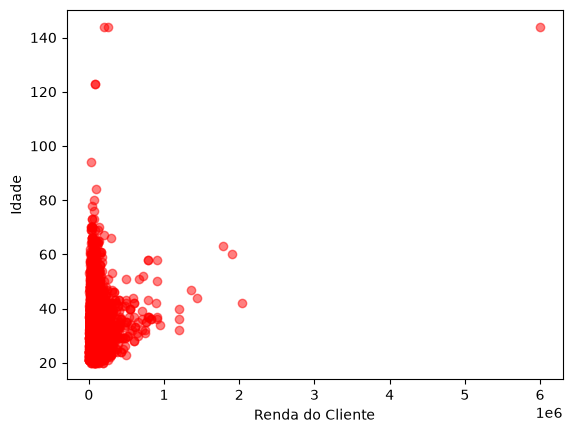

In [44]:
# Verificando a dispersão de renda em função da idade do cliente
plt.scatter(df["person_income"], df["person_age"], alpha=0.5, color="red")
plt.xlabel("Renda do Cliente")
plt.ylabel("Idade")
plt.show()

In [45]:
# crosstab entre o finalidade do emprestimo e o status do emprestimo
print(pd.crosstab(df['loan_intent'] ,df['loan_status'], margins=True))


loan_status            0     1    All
loan_intent                          
DEBTCONSOLIDATION   3722  1490   5212
EDUCATION           5342  1111   6453
HOMEIMPROVEMENT     2664   941   3605
MEDICAL             4450  1621   6071
PERSONAL            4423  1098   5521
VENTURE             4872   847   5719
All                25473  7108  32581


In [46]:
# Distribuição da inadimplência por nível de risco e situação de moradia
pd.crosstab(df['person_home_ownership'], [df['loan_status'], df["loan_grade"]])

loan_status               0                                 1                              
loan_grade                A     B     C    D    E   F  G    A     B    C     D    E   F   G
person_home_ownership                                                                      
MORTGAGE               5219  3729  1934  658  178  36  0  239   324  321   553  161  61  31
OTHER                    23    29    11    9    2   0  0    3     5    6    11    6   2   0
OWN                     860   770   464  264   26   7  0   66    34   31    18   31   8   5
RENT                   3602  4222  2710  554  137  28  1  765  1338  981  1559  423  99  27

In [47]:
# Média de comprometimento da renda por tipo de moradia e status do empréstimo
pd.crosstab(df["person_home_ownership"], df["loan_status"], values=df["loan_percent_income"], aggfunc="mean")

loan_status,0,1
person_home_ownership,,
MORTGAGE,0.146504,0.184882
OTHER,0.143784,0.300000
OWN,0.180013,0.297358
RENT,0.144611,0.264859


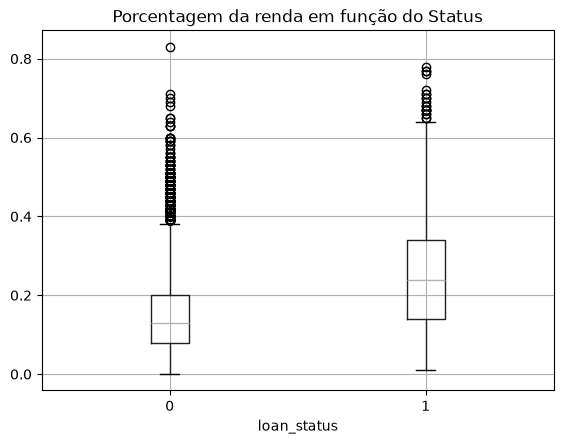

In [48]:
# boxplot da porcentagem da renda em função do status do emprestimo

df.boxplot(column = ["loan_percent_income"], by = "loan_status")
plt.title("Porcentagem da renda em função do Status")
plt.suptitle("")
plt.show()

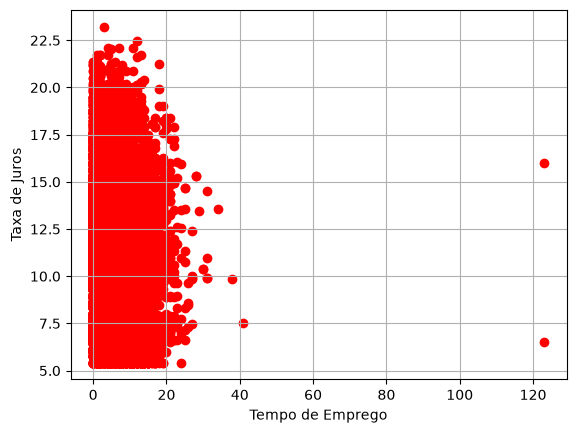

In [49]:
plt.scatter(df["person_emp_length"], df["loan_int_rate"], color="red")
plt.xlabel("Tempo de Emprego")
plt.ylabel("Taxa de Juros")
plt.grid()
plt.show()

Aqui tem 2 pessoas com mais de 120 anos de trabalho, vou remove-las, irei fazer a mesma coisa com as pessoas de idade > 110 que apareceram no grafico de dispersão de idade x renda


In [50]:
# Criando um array de indices onde o tempo de emprego é maior que 60
indices = df[df['person_emp_length'] > 60].index

# Dropando os registros do dataframe com base nos indices e criando um novo dataframe
novo_df = df.drop(indices)

# Criando um novo cross table com base no novo dataframe
pd.crosstab(novo_df["loan_status"],novo_df["person_home_ownership"], values=novo_df['person_emp_length'], aggfunc=['min','max'])

min                      max                  
person_home_ownership MORTGAGE OTHER  OWN RENT MORTGAGE OTHER   OWN  RENT
loan_status                                                              
0                          0.0   0.0  0.0  0.0     38.0  24.0  31.0  41.0
1                          0.0   0.0  0.0  0.0     34.0  11.0  17.0  27.0

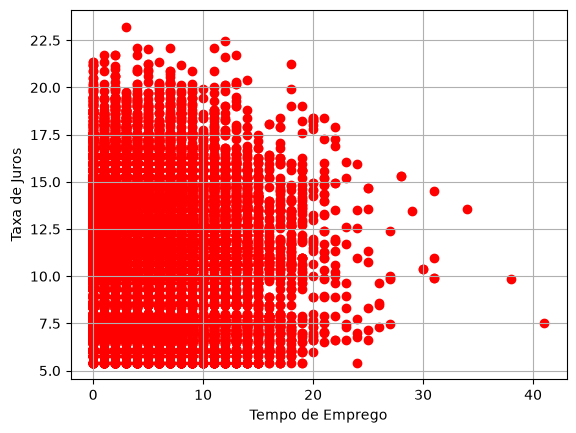

In [51]:
plt.scatter(novo_df["person_emp_length"], novo_df["loan_int_rate"], color="red")
plt.xlabel("Tempo de Emprego")
plt.ylabel("Taxa de Juros")
plt.grid()
plt.show()

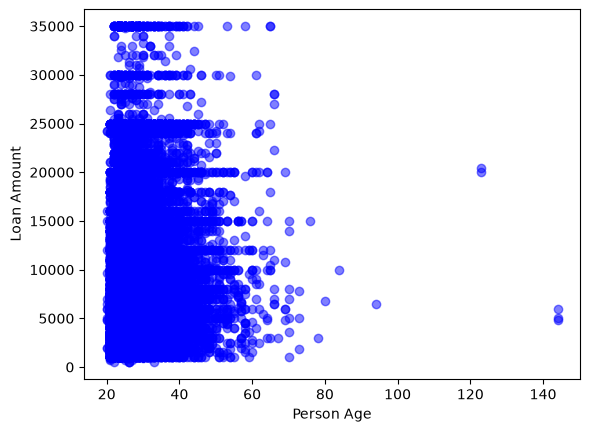

In [52]:
# Create the scatter plot for age and amount
plt.scatter(novo_df["person_age"], novo_df["loan_amnt"], c='blue', alpha=0.5)
plt.xlabel("Person Age")
plt.ylabel("Loan Amount")
plt.show()

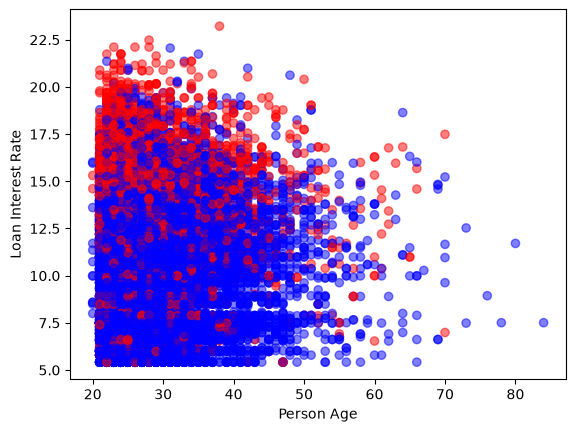

In [53]:
df_novo = novo_df.drop(novo_df[novo_df["person_age"] > 100].index)

# Create a scatter plot of age and interest rate
colors = ["blue","red"]
plt.scatter(df_novo["person_age"], df_novo["loan_int_rate"],
            c = df_novo['loan_status'],
            cmap = matplotlib.colors.ListedColormap(colors),
            alpha=0.5)
plt.xlabel("Person Age")
plt.ylabel("Loan Interest Rate")
plt.show()

Index(['person_emp_length', 'loan_int_rate'], dtype='str')
1    False
2    False
3    False
4    False
5    False
Name: person_emp_length, dtype: bool


/tmp/ipykernel_14681/1336890464.py:8: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df_novo["person_emp_length"].fillna((df_novo['person_emp_length'].median()), inplace=True)


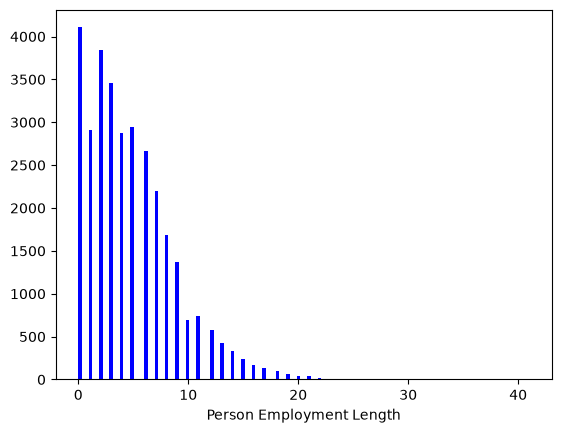

In [54]:
# Print a null value column array
print(df_novo.columns[df_novo.isnull().any()])

# Print the top five rows with nulls for employment length
print(df_novo["person_emp_length"].isnull().head())

# Impute the null values with the median value for all employment lengths
df_novo["person_emp_length"].fillna((df_novo['person_emp_length'].median()), inplace=True)

# Create a histogram of employment length
n, bins, patches = plt.hist(df_novo["person_emp_length"], bins='auto', color='blue')
plt.xlabel("Person Employment Length")
plt.show()

In [55]:
# Print the number of nulls
print(df_novo['loan_int_rate'].isnull().sum())

# Store the array on indices
indices = df_novo[df_novo['loan_int_rate'].isnull()].index

# Save the new data without missing data
df_novo_clean = df_novo.drop(indices)


3115
